In [1]:
%load_ext jupyter_black
%load_ext autoreload
%autoreload 2

import matplotlib.pyplot as plt
import numpy as np

from src.analysis.prox_crit import calc_db, minimize_klr_b
from src.analysis.prox_crit_confounds import CALC_DB_DEFAULTS, plot_d2_sweep
from src.models.branching_model.branching_network import (
    distance_to_criticality,
    params_for_distance,
    bn_aa_population,
    stationary_rate_aa,
    stationary_var_aa,
)
from src.config.paths import FIGURES_DIR
from src.utils.persist import save, load, list_saves, prune
from src.utils.binning import binning
from src.utils.plotting import PET10, add_linear_inset, save_fig
from src.analysis.autocorrelation import get_autocorrelation

PET10.use()  # default colour cycle
save_figures = True  # plots -> results/figures/prox_crit_confounds/ (sweep plots only when not debugging)

In [2]:
# define parameters
debugging = False

T = int(1e5)
R = 5
steady_rate = 0.2
seed = 123
distances = np.logspace(start=-4, stop=0, num=50, base=10)

# independent variable: window_lengths
Ns = np.logspace(start=2, stop=5, num=10, base=10).astype(int)

if debugging:
    T, R, steady_rate = int(1e5), 2, 0.2
    distances = np.logspace(start=-4, stop=0, num=6, base=10)
    Ns = np.logspace(start=2, stop=5, num=4, base=10).astype(int)

In [3]:
# generate the data
db_results = []  # db_results[i][j][r] = DbResult for distances[i], fuses[j], replica r
for i, distance in enumerate(distances):
    sigma, h = params_for_distance(rate=steady_rate, distance=distance)

    results_this_distance = []
    for N in Ns:

        A = bn_aa_population(N=N, sigma=sigma, T=T, h=h, R=R, seed=seed * i)

        results_this_fuse = []
        for r in range(R):
            result = calc_db(x=A[r], **CALC_DB_DEFAULTS)
            results_this_fuse.append(result)

        results_this_distance.append(results_this_fuse)

    db_results.append(results_this_distance)
    print(f"distance {i + 1}/{len(distances)} done")

path = save(
    "bn_aa_db_N" + ("_debug" if debugging else ""),
    db_results=db_results,
    distances=distances,
    Ns=Ns,
    params=dict(N=N, T=T, R=R, steady_rate=steady_rate, seed=seed),
    keep=(
        1 if debugging else None
    ),  # debug runs: keep only the newest; real runs: keep all
)

distance 1/50 done
distance 2/50 done
distance 3/50 done
distance 4/50 done
distance 5/50 done
distance 6/50 done
distance 7/50 done
distance 8/50 done
distance 9/50 done
distance 10/50 done
distance 11/50 done
distance 12/50 done
distance 13/50 done
distance 14/50 done
distance 15/50 done
distance 16/50 done
distance 17/50 done
distance 18/50 done
distance 19/50 done
distance 20/50 done
distance 21/50 done
distance 22/50 done
distance 23/50 done
distance 24/50 done
distance 25/50 done
distance 26/50 done
distance 27/50 done
distance 28/50 done
distance 29/50 done
distance 30/50 done
distance 31/50 done
distance 32/50 done
distance 33/50 done
distance 34/50 done
distance 35/50 done
distance 36/50 done
distance 37/50 done
distance 38/50 done
distance 39/50 done
distance 40/50 done
distance 41/50 done
distance 42/50 done
distance 43/50 done
distance 44/50 done
distance 45/50 done
distance 46/50 done
distance 47/50 done
distance 48/50 done
distance 49/50 done
distance 50/50 done
Saved dat

Loaded bn_aa_db_N__2026-11-20_014531.pkl (1.0 MB, git c0b24df)
  db_results : list, len 50
  distances  : ndarray float64 (50,)
  Ns         : ndarray int64 (10,)
  params     : dict, len 5
Saved results\figures\prox_crit_confounds\d2_vs_eps_network_size.png (468 kB, new)


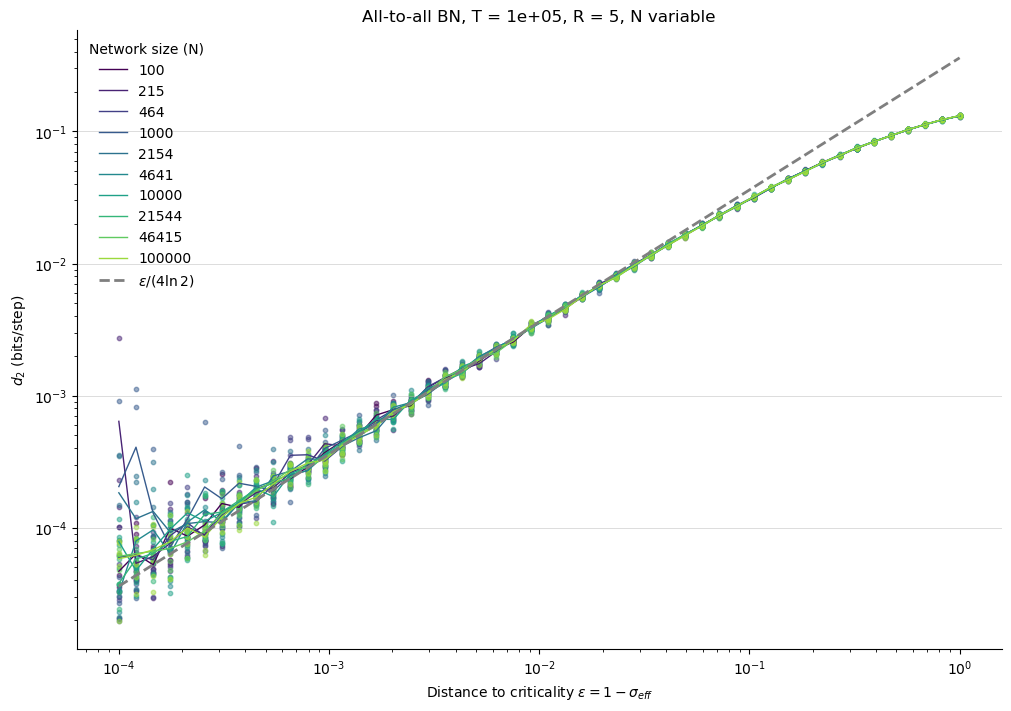

In [4]:
# plot it
data = load(
    "bn_aa_db_N" + ("_debug" if debugging else "")
)  # after a kernel restart: load("bn_aa_db_N") gets the newest run

p = data.params
fig, ax = plot_d2_sweep(
    distances=data.distances,
    db_results=data.db_results,
    values=data.Ns,
    legend_title="Network size (N)",
    title=rf"All-to-all BN, T = {p['T']:.4g}, R = {p['R']:.4g}, N variable, b = {CALC_DB_DEFAULTS['b']}, n = {CALC_DB_DEFAULTS['order']}",
)
if save_figures and not debugging:
    save_fig(fig, "prox_crit_confounds/d2_vs_eps_network_size")
plt.show()